In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "../outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [8]:
!pip install tensorflow matplotlib seaborn scikit-learn kaggle

# **Dataset Path and Class Check**

In [9]:
import os

dataset_path = DATA_DIR

classes = os.listdir(dataset_path)
print(f"Total number of classes: {len(classes)}")
print("\nClasses found:")
for c in sorted(classes):
    print(c)

Total number of classes: 38

Classes found:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mo

In [10]:
class_counts = {}
for cls in classes:
    cls_path = os.path.join(dataset_path, cls)
    class_counts[cls] = len(os.listdir(cls_path))

print(f"Total images: {sum(class_counts.values())}")

Total images: 54305


# **Class Distribution Visualisation**

/tmp/ipykernel_55/2818103301.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(sorted_counts.values()), y=list(sorted_counts.keys()), palette="viridis")


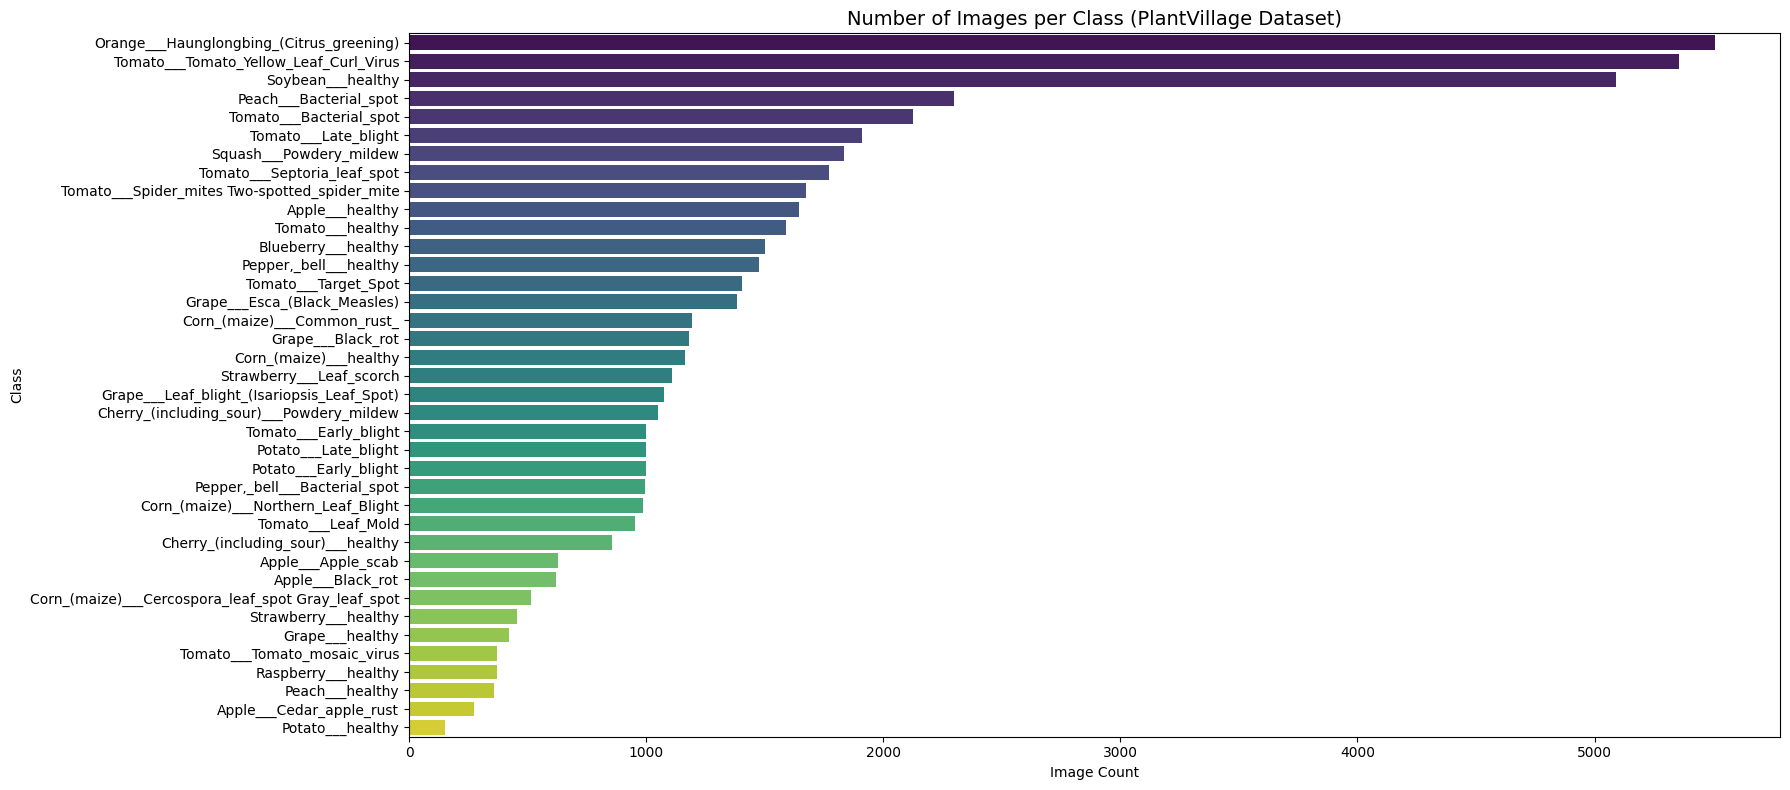

Min images in a class: 152
Max images in a class: 5507
Mean images per class: 1429.08


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort by count
sorted_counts = dict(sorted(class_counts.items(), key=lambda x: x[1], reverse=True))

plt.figure(figsize=(18, 8))
sns.barplot(x=list(sorted_counts.values()), y=list(sorted_counts.keys()), palette="viridis")
plt.title("Number of Images per Class (PlantVillage Dataset)", fontsize=14)
plt.xlabel("Image Count")
plt.ylabel("Class")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

print("Min images in a class:", min(sorted_counts.values()))
print("Max images in a class:", max(sorted_counts.values()))
print("Mean images per class:", round(sum(sorted_counts.values())/len(sorted_counts), 2))

# **Sample Images from Each Class**

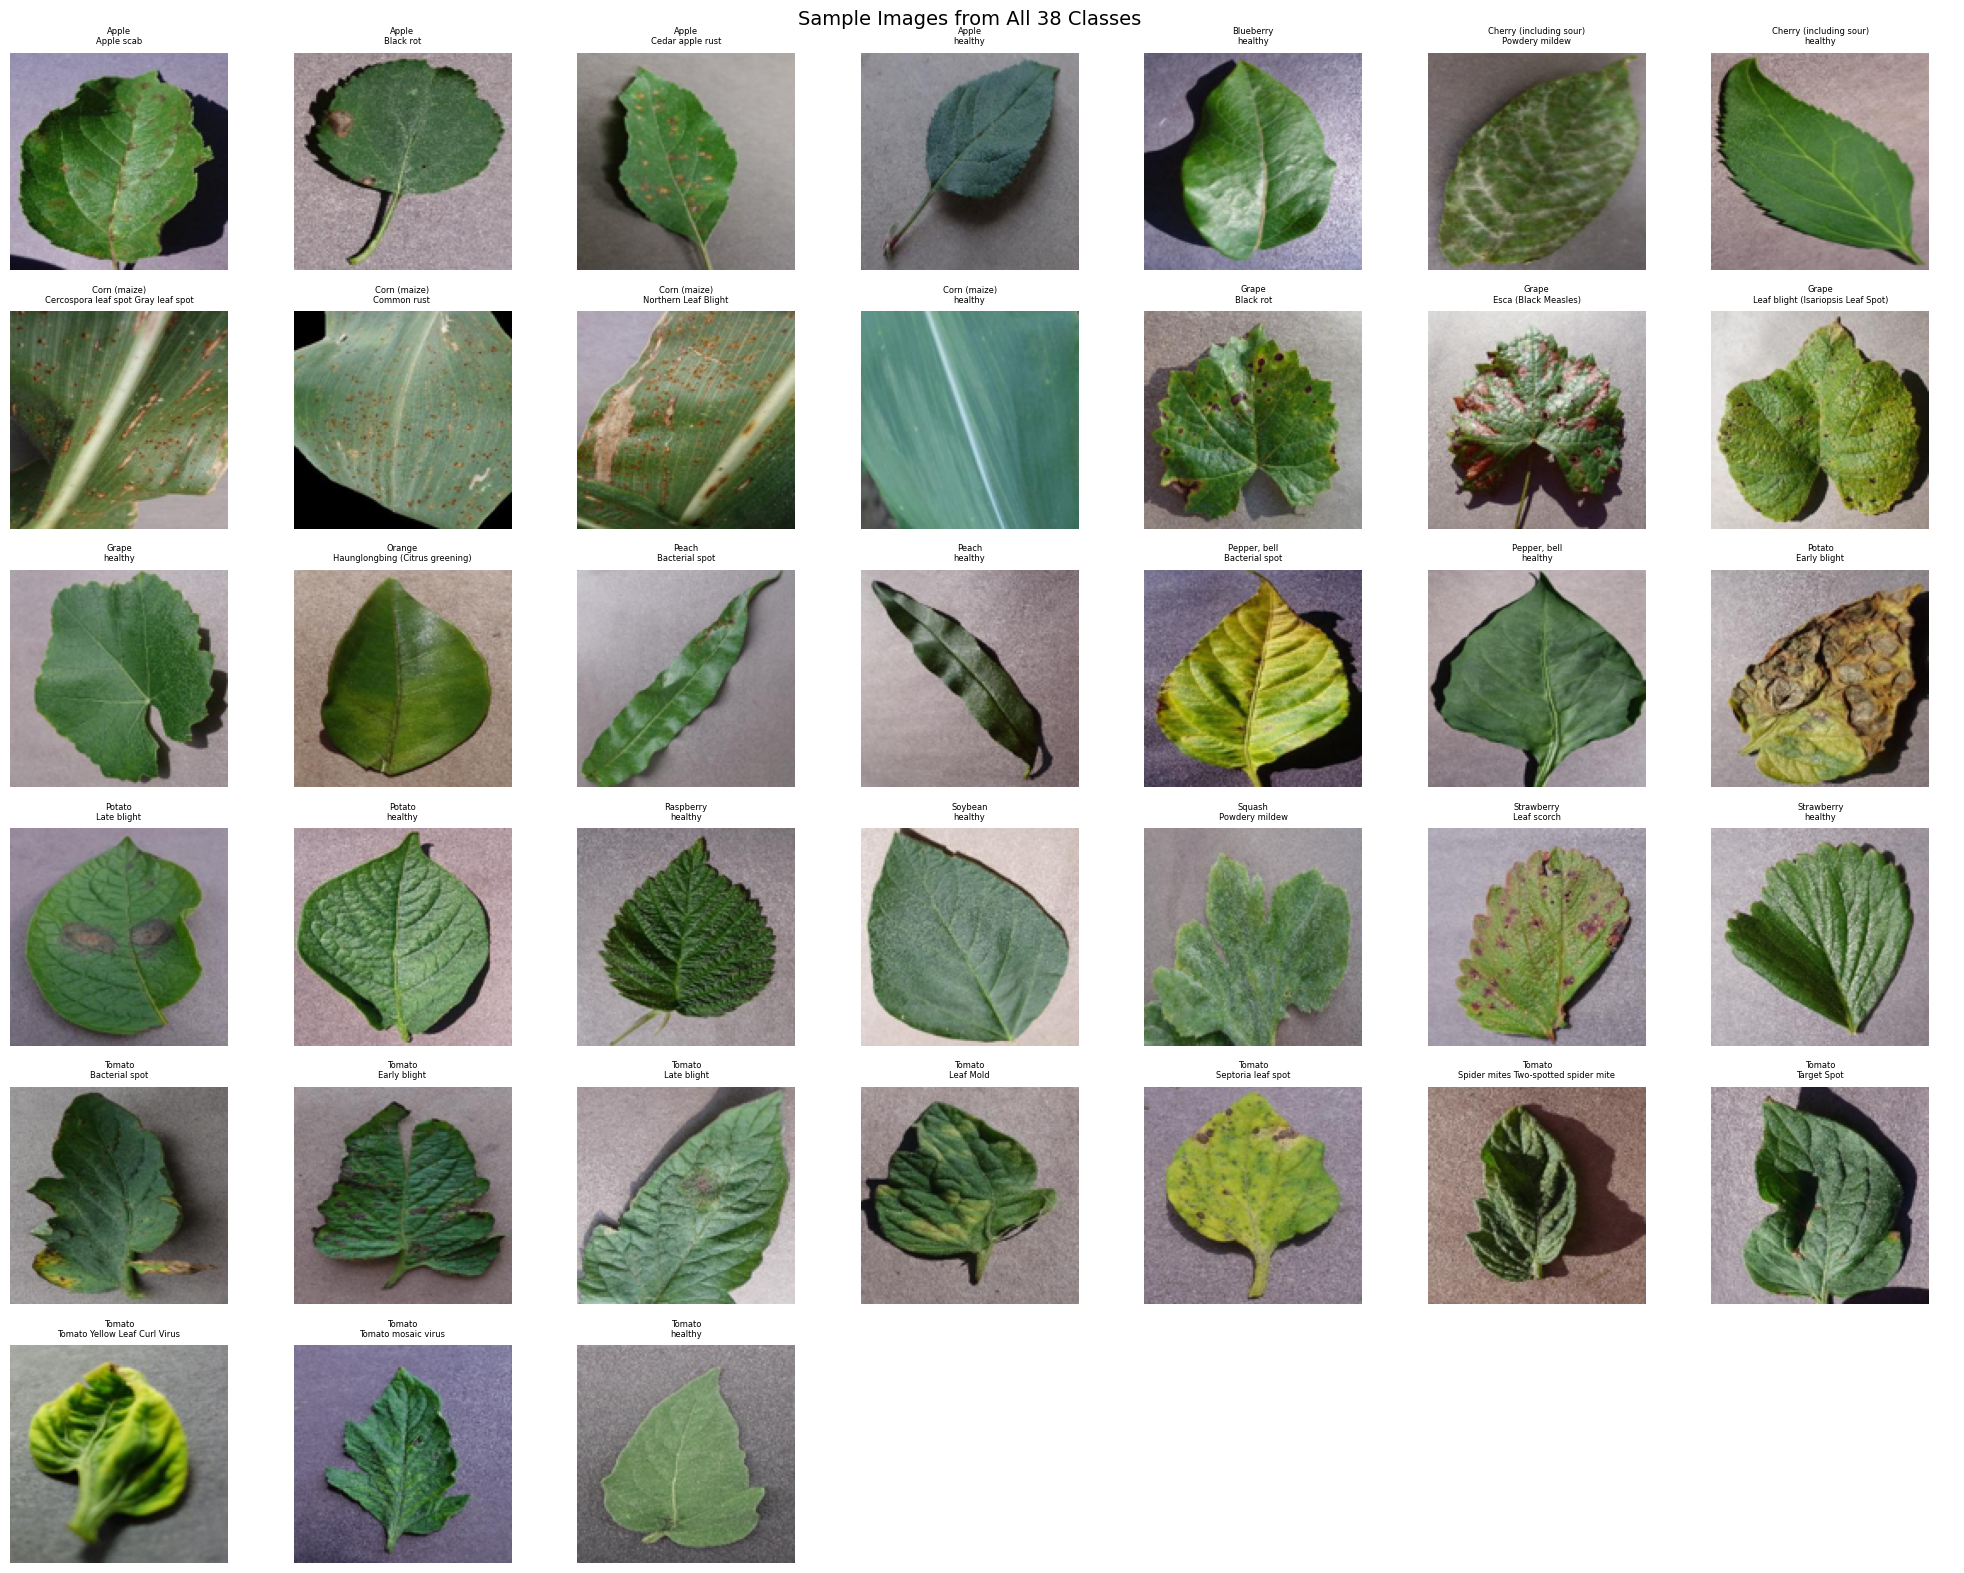

In [12]:
import random
from PIL import Image
import numpy as np

fig, axes = plt.subplots(6, 7, figsize=(20, 16))
axes = axes.flatten()

for i, cls in enumerate(sorted(classes)):
    cls_path = os.path.join(dataset_path, cls)
    img_file = random.choice(os.listdir(cls_path))
    img = Image.open(os.path.join(cls_path, img_file)).resize((128, 128))
    axes[i].imshow(img)
    axes[i].set_title(cls.replace("___", "\n").replace("_", " "), fontsize=6)
    axes[i].axis("off")

# Hiding any unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Sample Images from All 38 Classes", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150)
plt.show()

# **Image Properties Analysis**

In [13]:
# Checking image sizes and modes across dataset
sizes = []
modes = []

sample_classes = random.sample(classes, 10)  # sampling 10 classes for speed

for cls in sample_classes:
    cls_path = os.path.join(dataset_path, cls)
    for img_file in random.sample(os.listdir(cls_path), min(20, len(os.listdir(cls_path)))):
        img = Image.open(os.path.join(cls_path, img_file))
        sizes.append(img.size)
        modes.append(img.mode)

unique_sizes = set(sizes)
unique_modes = set(modes)

print(f"Unique image sizes found: {unique_sizes}")
print(f"Unique image modes (colour spaces): {unique_modes}")
print(f"Most common size: {max(set(sizes), key=sizes.count)}")

Unique image sizes found: {(256, 256)}
Unique image modes (colour spaces): {'RGB'}
Most common size: (256, 256)


# **Pixel Intensity & Colour Channel Analysis**

In [14]:
# Analysing RGB channel distributions for healthy vs diseased
def get_channel_stats(class_name, n_samples=50):
    cls_path = os.path.join(dataset_path, class_name)
    files = random.sample(os.listdir(cls_path), min(n_samples, len(os.listdir(cls_path))))
    r, g, b = [], [], []
    for f in files:
        img = np.array(Image.open(os.path.join(cls_path, f)).resize((128, 128)))
        if img.ndim == 3:
            r.append(img[:,:,0].mean())
            g.append(img[:,:,1].mean())
            b.append(img[:,:,2].mean())
    return np.mean(r), np.mean(g), np.mean(b)

# Comparing healthy vs diseased class
pairs = [
    ("Tomato___healthy", "Tomato___Early_blight"),
    ("Apple___healthy", "Apple___Apple_scab"),
    ("Potato___healthy", "Potato___Late_blight")
]

print(f"{'Class':<45} {'R':>6} {'G':>6} {'B':>6}")
print("-" * 65)
for healthy, diseased in pairs:
    for cls in [healthy, diseased]:
        r, g, b = get_channel_stats(cls)
        print(f"{cls:<45} {r:>6.1f} {g:>6.1f} {b:>6.1f}")
    print()

Class                                              R      G      B
-----------------------------------------------------------------
Tomato___healthy                               114.5  119.1  110.4
Tomato___Early_blight                          108.7  113.7  101.8

Apple___healthy                                111.9  117.9  115.4
Apple___Apple_scab                             105.0  115.2  105.1

Potato___healthy                               124.9  132.6  112.2
Potato___Late_blight                           123.2  123.7  107.6



# **Feature Extraction (HOG + Colour Histograms)**

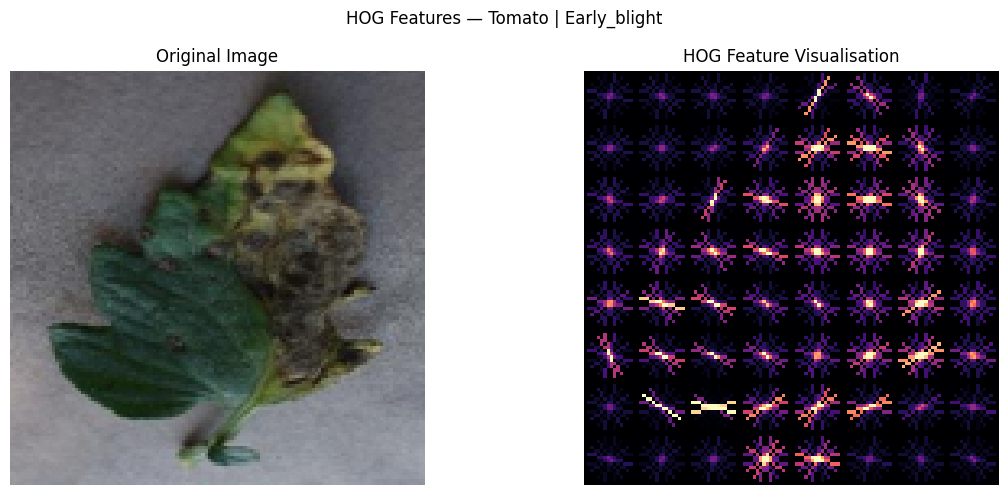

HOG feature vector length: 512


In [15]:
from skimage.feature import hog
from skimage import exposure

# HOG feature visualisation on a sample image
sample_cls = "Tomato___Early_blight"
sample_img_path = os.path.join(dataset_path, sample_cls, os.listdir(os.path.join(dataset_path, sample_cls))[0])
sample_img = np.array(Image.open(sample_img_path).resize((128, 128)).convert("RGB"))

# Computing HOG
fd, hog_image = hog(sample_img, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), visualize=True, channel_axis=-1)
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.imshow(sample_img)
ax1.set_title("Original Image")
ax1.axis("off")
ax2.imshow(hog_image_rescaled, cmap="magma")
ax2.set_title("HOG Feature Visualisation")
ax2.axis("off")
plt.suptitle(f"HOG Features — {sample_cls.replace('___', ' | ')}", fontsize=12)
plt.tight_layout()
plt.savefig("hog_features.png", dpi=150)
plt.show()

print(f"HOG feature vector length: {len(fd)}")

# **Colour Histogram Comparison**

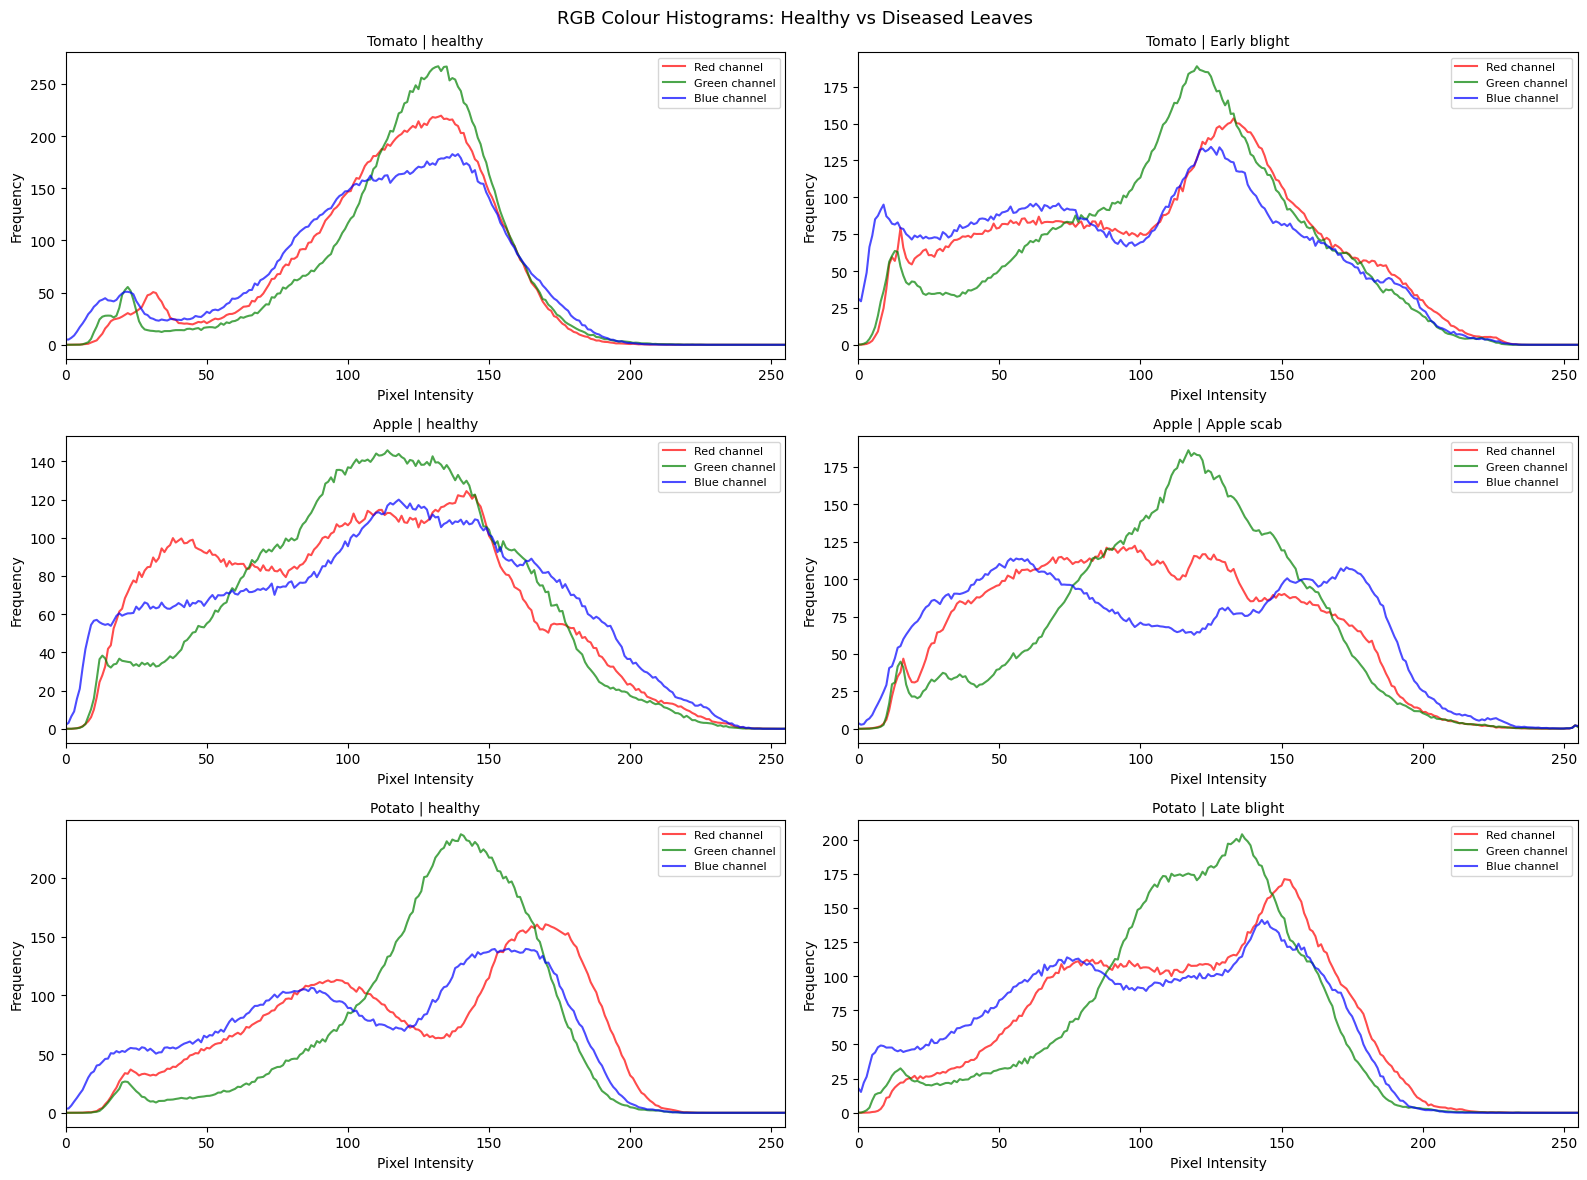

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os, random

def get_avg_histogram(class_name, n_samples=50):
    cls_path = os.path.join(dataset_path, class_name)
    files = random.sample(os.listdir(cls_path), min(n_samples, len(os.listdir(cls_path))))
    hist_r = np.zeros(256)
    hist_g = np.zeros(256)
    hist_b = np.zeros(256)
    for f in files:
        img = np.array(Image.open(os.path.join(cls_path, f)).resize((128, 128)))
        if img.ndim == 3:
            hist_r += np.histogram(img[:,:,0], bins=256, range=(0,255))[0]
            hist_g += np.histogram(img[:,:,1], bins=256, range=(0,255))[0]
            hist_b += np.histogram(img[:,:,2], bins=256, range=(0,255))[0]
    return hist_r/n_samples, hist_g/n_samples, hist_b/n_samples

pairs = [
    ("Tomato___healthy", "Tomato___Early_blight"),
    ("Apple___healthy", "Apple___Apple_scab"),
    ("Potato___healthy", "Potato___Late_blight")
]

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

for row, (healthy, diseased) in enumerate(pairs):
    for col, cls in enumerate([healthy, diseased]):
        r, g, b = get_avg_histogram(cls)
        ax = axes[row][col]
        ax.plot(r, color='red', alpha=0.7, label='Red channel')
        ax.plot(g, color='green', alpha=0.7, label='Green channel')
        ax.plot(b, color='blue', alpha=0.7, label='Blue channel')
        ax.set_title(cls.replace("___", " | ").replace("_", " "), fontsize=10)
        ax.set_xlabel("Pixel Intensity")
        ax.set_ylabel("Frequency")
        ax.legend(fontsize=8)
        ax.set_xlim(0, 255)

plt.suptitle("RGB Colour Histograms: Healthy vs Diseased Leaves", fontsize=13)
plt.tight_layout()
plt.savefig("colour_histograms.png", dpi=150)
plt.show()

# **Class Imbalance Handling Strategy**

In [17]:
import pandas as pd

# Creating a summary dataframe
df_counts = pd.DataFrame(list(class_counts.items()), columns=['Class', 'Count'])
df_counts['Plant'] = df_counts['Class'].apply(lambda x: x.split('___')[0])
df_counts['Condition'] = df_counts['Class'].apply(lambda x: x.split('___')[1])
df_counts['Is_Healthy'] = df_counts['Condition'].str.lower() == 'healthy'

print("=== Dataset Summary ===")
print(f"Total classes: {len(df_counts)}")
print(f"Healthy classes: {df_counts['Is_Healthy'].sum()}")
print(f"Diseased classes: {(~df_counts['Is_Healthy']).sum()}")
print(f"\nUnique plants: {df_counts['Plant'].nunique()}")
print(df_counts['Plant'].value_counts().to_string())

print("\n=== Classes needing augmentation (< 500 images) ===")
print(df_counts[df_counts['Count'] < 500][['Class', 'Count']].to_string())

=== Dataset Summary ===
Total classes: 38
Healthy classes: 12
Diseased classes: 26

Unique plants: 14
Plant
Tomato                     10
Grape                       4
Apple                       4
Corn_(maize)                4
Potato                      3
Strawberry                  2
Cherry_(including_sour)     2
Pepper,_bell                2
Peach                       2
Orange                      1
Squash                      1
Soybean                     1
Blueberry                   1
Raspberry                   1

=== Classes needing augmentation (< 500 images) ===
                           Class  Count
2                Grape___healthy    423
6               Potato___healthy    152
12               Peach___healthy    360
20      Apple___Cedar_apple_rust    275
25  Tomato___Tomato_mosaic_virus    373
26          Strawberry___healthy    456
33           Raspberry___healthy    371


# **Preprocessing & Augmentation Pipeline**

In [18]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ── Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# ── Class weights to handle imbalance
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_names = sorted(os.listdir(dataset_path))
class_indices = {cls: i for i, cls in enumerate(class_names)}

# Building labels list
all_labels = []
for cls in class_names:
    cls_path = os.path.join(dataset_path, cls)
    all_labels.extend([class_indices[cls]] * len(os.listdir(cls_path)))

all_labels = np.array(all_labels)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_labels),
    y=all_labels
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights computed for", len(class_weight_dict), "classes")
print("Sample weights (first 5):", {k: round(v, 3) for k, v in list(class_weight_dict.items())[:5]})

Class weights computed for 38 classes
Sample weights (first 5): {0: np.float64(2.268), 1: np.float64(2.301), 2: np.float64(5.197), 3: np.float64(0.869), 4: np.float64(0.951)}


In [19]:
# ── Data Generators with Augmentation

# Traininging generator — heavy augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)

# Validation generator — only rescale, no augmentation
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Loading training data
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED,
    shuffle=True
)

# Loading validation data
val_generator = val_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED,
    shuffle=False
)

print(f"\nTraining samples:   {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Number of classes:  {train_generator.num_classes}")

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.

Training samples:   43456
Validation samples: 10849
Number of classes:  38


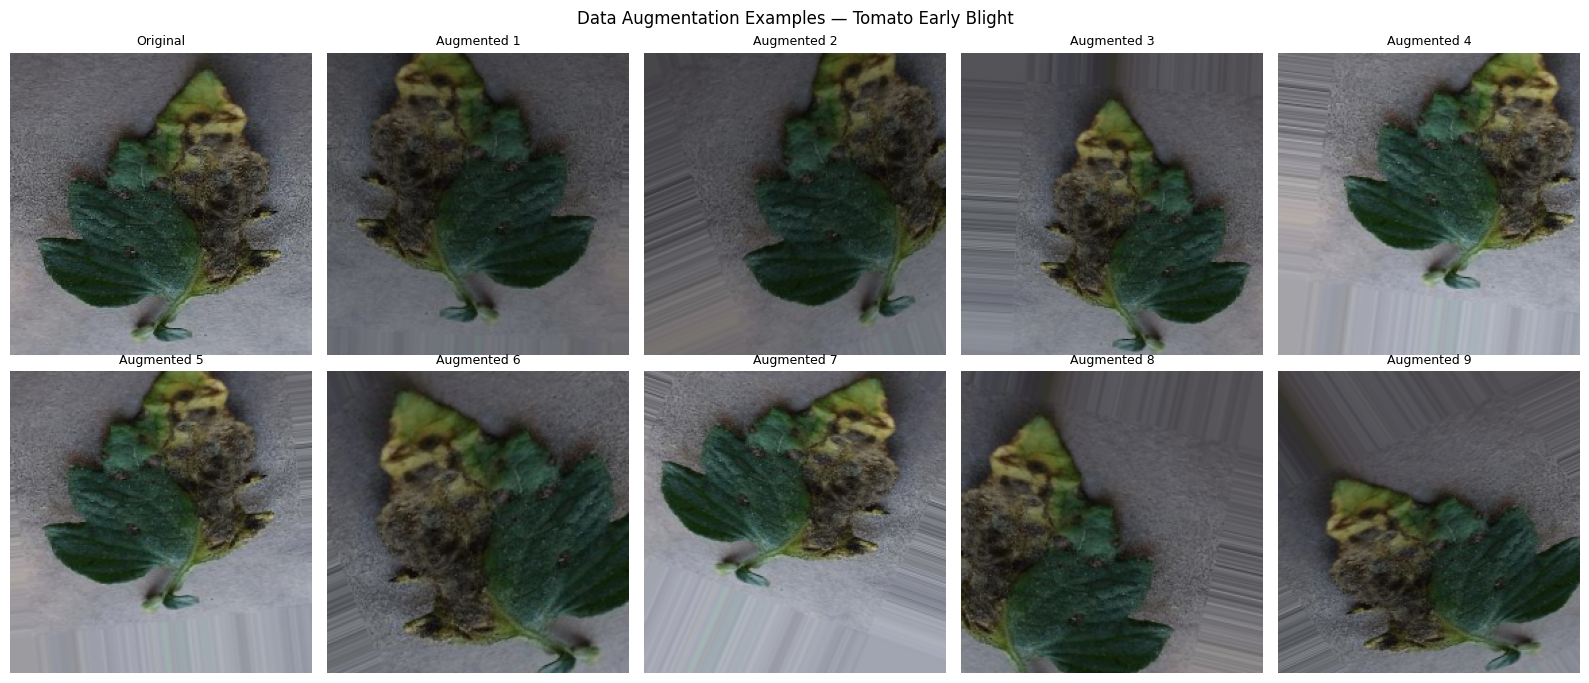

In [20]:
# ── Visualising Augmentation Effect
from tensorflow.keras.preprocessing.image import load_img, img_to_array

sample_path = os.path.join(dataset_path, "Tomato___Early_blight",
              os.listdir(os.path.join(dataset_path, "Tomato___Early_blight"))[0])

sample_img = load_img(sample_path, target_size=IMG_SIZE)
sample_arr = img_to_array(sample_img)
sample_arr = sample_arr.reshape((1,) + sample_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()
axes[0].imshow(sample_img)
axes[0].set_title("Original", fontsize=9)
axes[0].axis("off")

for i, batch in enumerate(aug_gen.flow(sample_arr, batch_size=1), 1):
    if i >= 10: break
    axes[i].imshow(batch[0].astype("uint8"))
    axes[i].set_title(f"Augmented {i}", fontsize=9)
    axes[i].axis("off")

plt.suptitle("Data Augmentation Examples — Tomato Early Blight", fontsize=12)
plt.tight_layout()
plt.savefig("augmentation_examples.png", dpi=150)
plt.show()

# **Model 1: Baseline CNN from Scratch**

In [ ]:
import shutil, os
print("Copying dataset to local storage...")
shutil.copytree(
    DATA_DIR,
    OUTPUT_DIR + "/plantvillage_local"
)
print("Done!")
print(os.listdir(OUTPUT_DIR + "/plantvillage_local")[:5]) 

In [51]:
import tensorflow as tf
import os, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
print("Using single GPU:", tf.config.list_physical_devices('GPU'))

Using single GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [52]:
# ── Config
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
dataset_path = OUTPUT_DIR + "/plantvillage_local"

In [53]:
def build_baseline_cnn(num_classes=38):
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(224, 224, 3)),
        BatchNormalization(),
        Conv2D(32, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),
        Dropout(0.25),
        Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(64, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),
        Dropout(0.25),
        Conv2D(128, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),
        Dropout(0.4),
        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

In [55]:
baseline_model = build_baseline_cnn()
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [56]:
# ── Generators
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    dataset_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='training', seed=SEED, shuffle=True
)
val_generator = val_datagen.flow_from_directory(
    dataset_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='validation', seed=SEED, shuffle=False
)
print(f"Train: {train_generator.samples} | Val: {val_generator.samples}")

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.
Train: 43456 | Val: 10849


In [48]:
# ── Class weights
class_names = sorted(os.listdir(dataset_path))
class_indices = {cls: i for i, cls in enumerate(class_names)}
all_labels = []
for cls in class_names:
    cls_path = os.path.join(dataset_path, cls)
    all_labels.extend([class_indices[cls]] * len(os.listdir(cls_path)))
all_labels = np.array(all_labels)
class_weights = compute_class_weight(
    class_weight='balanced', classes=np.unique(all_labels), y=all_labels)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights computed:", len(class_weight_dict), "classes")

Class weights computed: 38 classes


In [57]:
# ── STEP 7: Callbacks & Train
checkpoint_path = OUTPUT_DIR + "/baseline_best.keras"
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

print("Training Baseline CNN...")
baseline_history = baseline_model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

Training Baseline CNN...
Epoch 1/20
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.3175 - loss: 2.5007
Epoch 1: val_accuracy improved from -inf to 0.38160, saving model to /kaggle/working/baseline_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 557s 404ms/step - accuracy: 0.3176 - loss: 2.5003 - val_accuracy: 0.3816 - val_loss: 3.6787 - learning_rate: 0.0010
Epoch 2/20
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.6429 - loss: 1.1193
Epoch 2: val_accuracy improved from 0.38160 to 0.57968, saving model to /kaggle/working/baseline_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 546s 402ms/step - accuracy: 0.6430 - loss: 1.1192 - val_accuracy: 0.5797 - val_loss: 2.4311 - learning_rate: 0.0010
Epoch 3/20
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.6762 - loss: 0.9893
Epoch 3: val_accuracy improved from 0.57968 to 0.74173, saving model to /kaggle/working/baseline_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 550s 405ms/step - accuracy: 0.6762 - loss: 0.9892 - val_acc

In [58]:
def plot_history(history, model_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax1.set_title(f'{model_name} — Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True)
    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Val Loss')
    ax2.set_title(f'{model_name} — Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True)
    plt.suptitle(f'{model_name} Training History', fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{model_name.replace(' ', '_')}_history.png", dpi=150)
    plt.show()

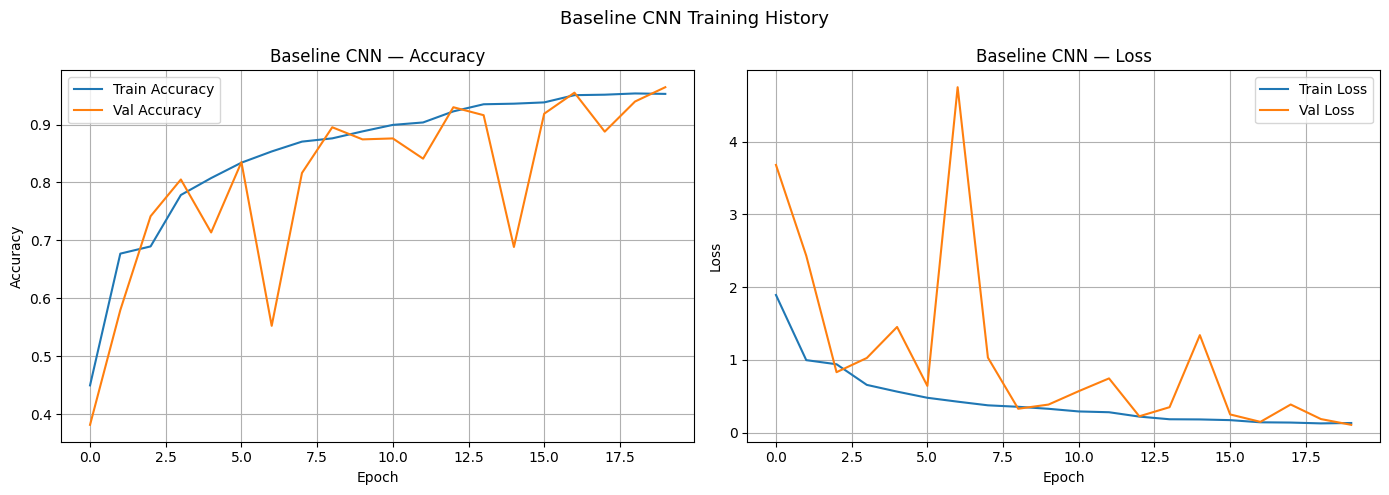

Training history saved!


In [59]:
# ── Plot & Save
plot_history(baseline_history, "Baseline CNN")

pd.DataFrame(baseline_history.history).to_csv(
    OUTPUT_DIR + "/baseline_history.csv", index=False)
print("Training history saved!")

# **CNN Model Evaluation**

In [60]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

val_generator.reset()

print("Generating predictions...")
y_pred_probs = baseline_model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.classes

# Class names
class_labels = list(val_generator.class_indices.keys())

# Classification report
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=3))

Generating predictions...
340/340 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step

=== Classification Report ===
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.984     0.992     0.988       126
                                 Apple___Black_rot      0.961     0.992     0.976       124
                          Apple___Cedar_apple_rust      1.000     0.982     0.991        55
                                   Apple___healthy      0.905     0.982     0.942       329
                               Blueberry___healthy      0.990     0.973     0.982       300
          Cherry_(including_sour)___Powdery_mildew      0.990     0.962     0.976       210
                 Cherry_(including_sour)___healthy      1.000     0.959     0.979       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.824     0.961     0.887       102
                       Corn_(maize)___Common_rust_      1.000     1.000

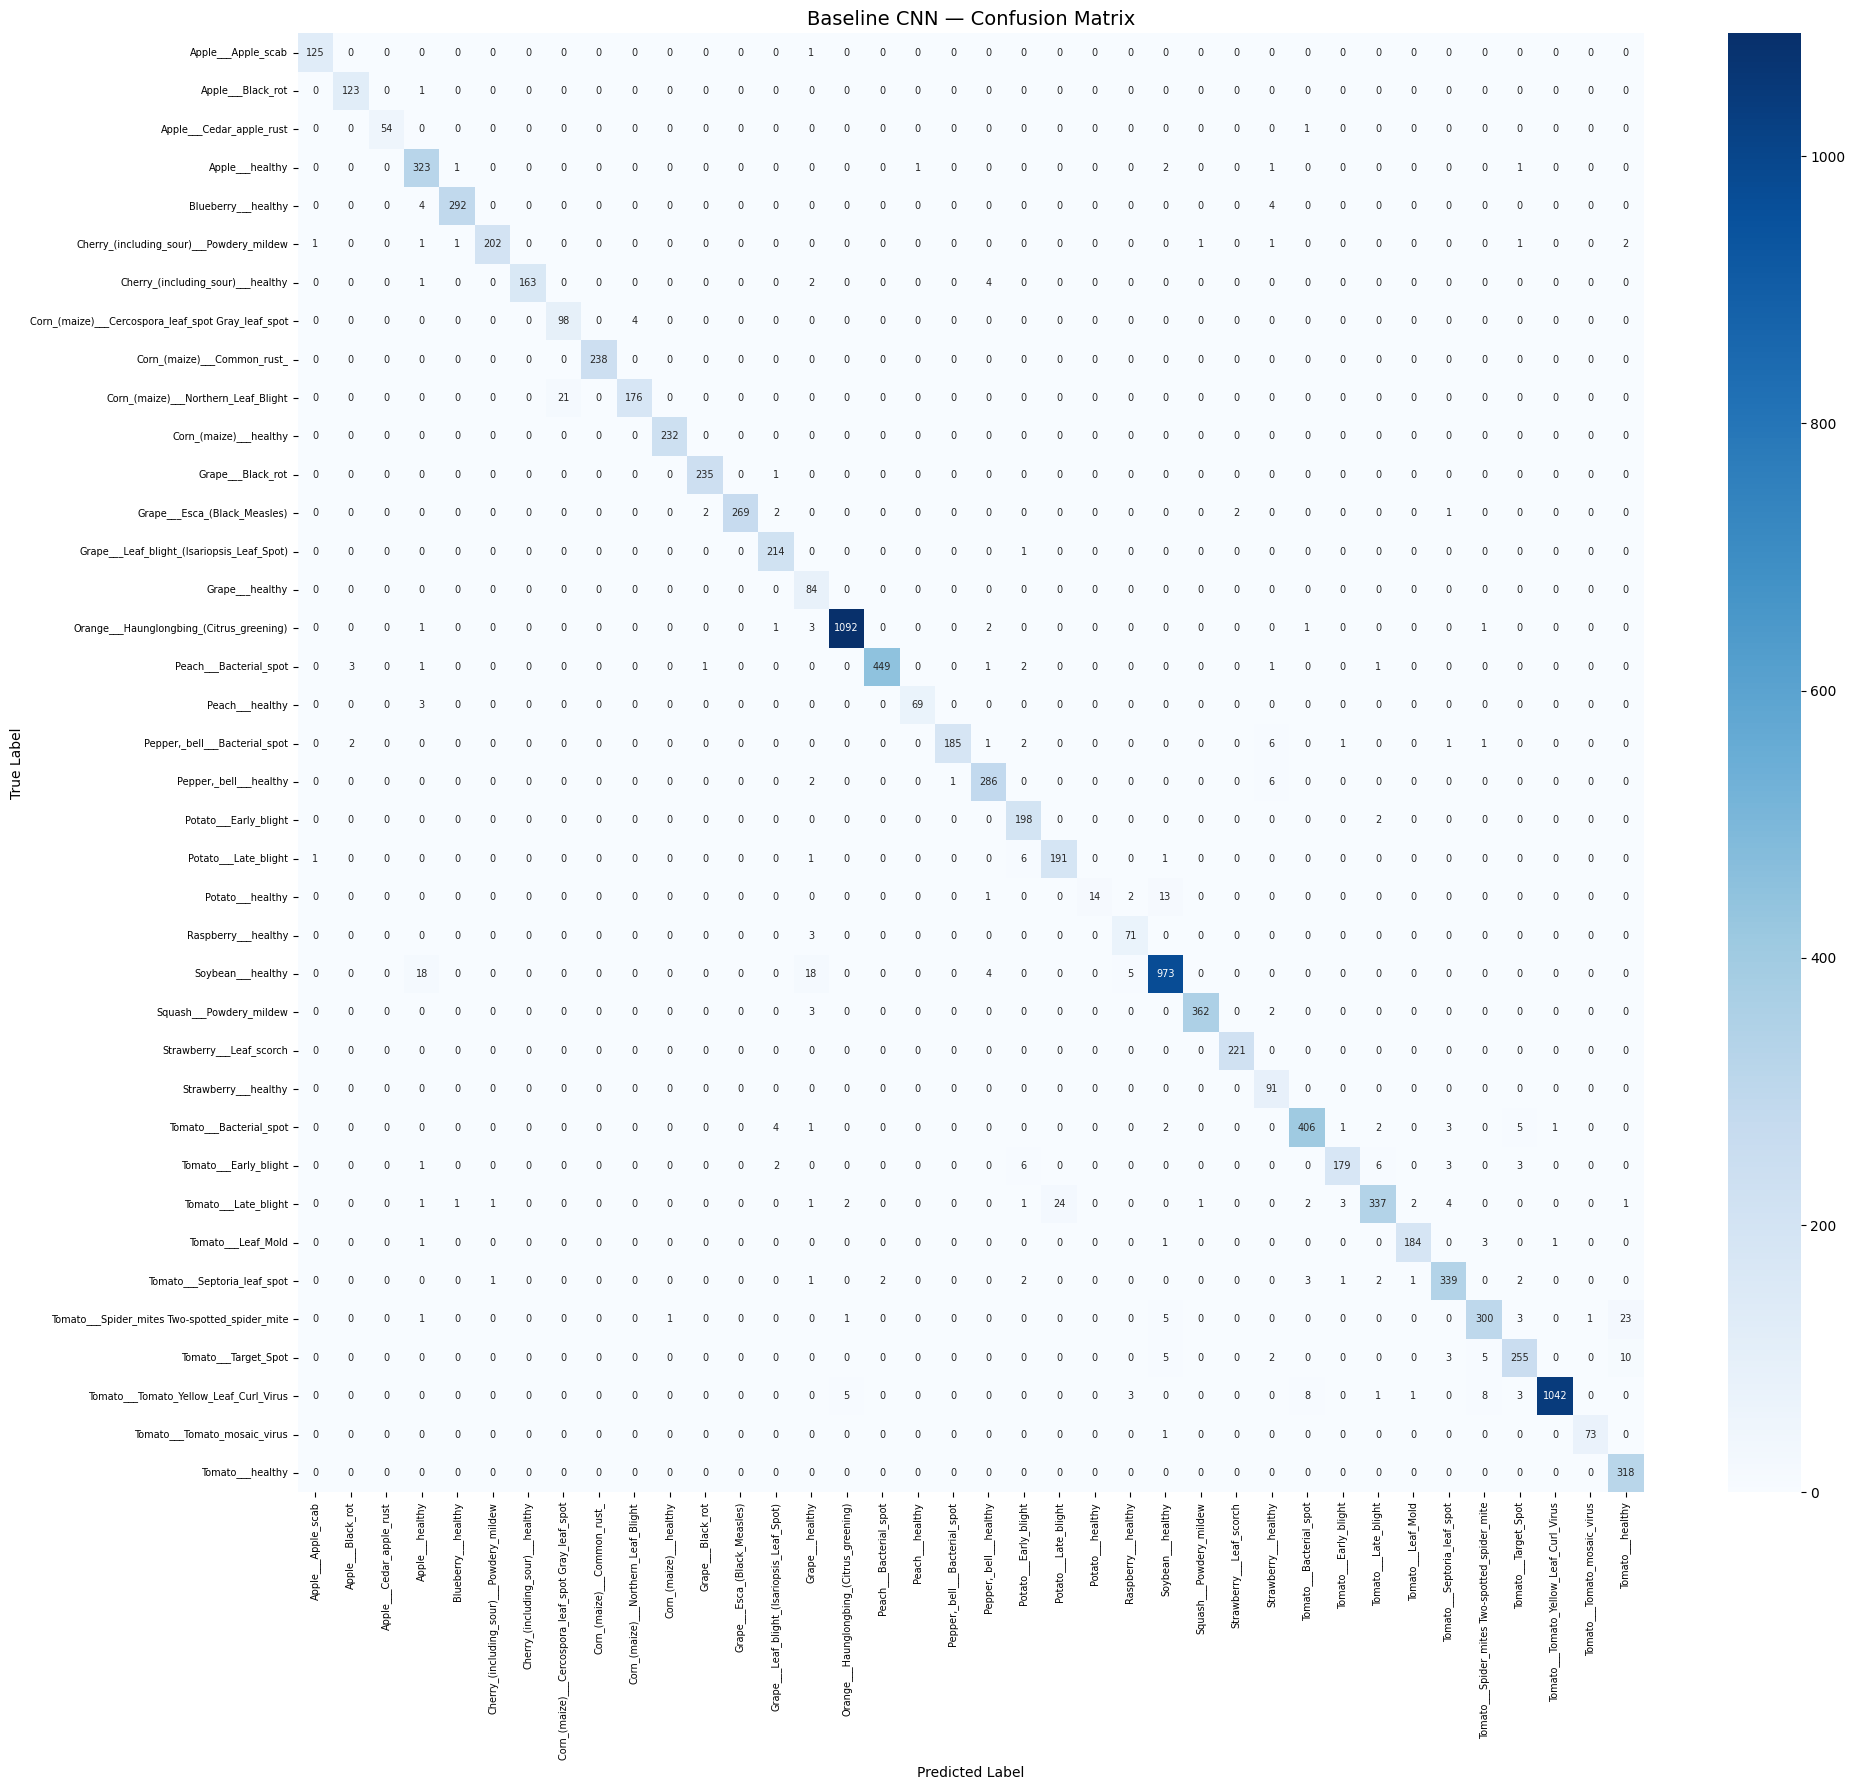

In [61]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 18))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels,
            annot_kws={"size": 7})
plt.title("Baseline CNN — Confusion Matrix", fontsize=14)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/baseline_confusion_matrix.png", dpi=150)
plt.show()

In [62]:
# Overall metrics summary
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

print("=== Overall Metrics ===")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"F1 Score (weighted):   {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Precision (weighted):  {precision_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Recall (weighted):     {recall_score(y_true, y_pred, average='weighted'):.4f}")

=== Overall Metrics ===
Accuracy:  0.9644
F1 Score (weighted):   0.9646
Precision (weighted):  0.9668
Recall (weighted):     0.9644


# **Model 2: EfficientNetB0 Transfer Learning**

In [65]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization

# ── Building EfficientNet Transfer Learning Model 
def build_efficientnet(num_classes=38):
    # Loading pretrained base — exclude top classifier
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    # Freezing base layers initially
    base_model.trainable = False

    # Adding custom classifier head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)
    return model, base_model

efficientnet_model, base_model = build_efficientnet()
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Total layers: {len(efficientnet_model.layers)}")
print(f"Trainable layers (frozen base): {sum(1 for l in efficientnet_model.layers if l.trainable)}")
efficientnet_model.summary()

Total layers: 245
Trainable layers (frozen base): 7


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ input_layer_8[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 224, 224,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,851,657 (18.51 MB)

 Trainable params: 799,526 (3.05 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [66]:
# Training classifier head only (base frozen) 
checkpoint_path_eff = OUTPUT_DIR + "/efficientnet_best.keras"

callbacks_eff = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(checkpoint_path_eff, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

# EfficientNet specific generators (NO rescaling)
efficientnet_train_datagen = ImageDataGenerator(
    validation_split=0.2,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)
efficientnet_val_datagen = ImageDataGenerator(
    validation_split=0.2
)
efficientnet_train_gen = efficientnet_train_datagen.flow_from_directory(
    dataset_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='training', seed=SEED, shuffle=True
)
efficientnet_val_gen = efficientnet_val_datagen.flow_from_directory(
    dataset_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='validation', seed=SEED, shuffle=False
)
print(f"Train: {efficientnet_train_gen.samples} | Val: {efficientnet_val_gen.samples}")


print("Phase 1: Training classifier head (base frozen)...")
phase1_history = efficientnet_model.fit(
    efficientnet_train_gen,
    epochs=10,
    validation_data=efficientnet_val_gen,
    class_weight=class_weight_dict,
    callbacks=callbacks_eff,
    verbose=1
)

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.
Train: 43456 | Val: 10849
Phase 1: Training classifier head (base frozen)...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - accuracy: 0.5947 - loss: 1.5611
Epoch 1: val_accuracy improved from -inf to 0.86367, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 553s 393ms/step - accuracy: 0.5948 - loss: 1.5607 - val_accuracy: 0.8637 - val_loss: 0.4208 - learning_rate: 0.0010
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.8075 - loss: 0.6427
Epoch 2: val_accuracy improved from 0.86367 to 0.90783, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 517s 380ms/step - accuracy: 0.8075 - loss: 0.6426 - val_accuracy: 0.9078 - val_loss: 0.2799 - learning_rate: 0.0010
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.8369 - loss: 0.5494
Epoch 3: val_accuracy improved from 0.90783 to 0.91041, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 515s 379ms/step - accuracy: 0.8369 - loss: 0.5493 - val_accuracy: 0.9104

In [68]:
# ── Fine-tuning 
print("Loading best Phase 1 weights and fine-tuning...")
efficientnet_model.load_weights(checkpoint_path_eff)

for layer in efficientnet_model.layers:
    layer.trainable = True
for layer in efficientnet_model.layers[:100]:
    layer.trainable = False

print(f"Trainable layers after unfreezing: {sum(1 for l in efficientnet_model.layers if l.trainable)}")
print(f"Frozen layers: {sum(1 for l in efficientnet_model.layers if not l.trainable)}")

# Recompiling with very low learning rate
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_eff_p2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(checkpoint_path_eff, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-8, verbose=1)
]

print("Phase 2: Fine-tuning...")
phase2_history = efficientnet_model.fit(
    efficientnet_train_gen,
    epochs=15,
    validation_data=efficientnet_val_gen,
    class_weight=class_weight_dict,
    callbacks=callbacks_eff_p2,
    verbose=1
)

Loading best Phase 1 weights and fine-tuning...


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 74 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Trainable layers after unfreezing: 145
Frozen layers: 100
Phase 2: Fine-tuning...
Epoch 1/15


2026-04-17 19:26:17.274119: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-17 19:26:17.428108: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.6186 - loss: 1.4542
Epoch 1: val_accuracy improved from -inf to 0.88036, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 588s 399ms/step - accuracy: 0.6187 - loss: 1.4539 - val_accuracy: 0.8804 - val_loss: 0.3828 - learning_rate: 1.0000e-05
Epoch 2/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - accuracy: 0.8042 - loss: 0.6023
Epoch 2: val_accuracy improved from 0.88036 to 0.91695, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 539s 397ms/step - accuracy: 0.8042 - loss: 0.6023 - val_accuracy: 0.9170 - val_loss: 0.2557 - learning_rate: 1.0000e-05
Epoch 3/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.8547 - loss: 0.4610
Epoch 3: val_accuracy improved from 0.91695 to 0.93594, saving model to /kaggle/working/efficientnet_best.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 529s 389ms/step - accuracy: 0.8547 - loss: 0.4610 - val_accuracy: 0.9359 - 

# **EfficientNet Evaluation**

In [69]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
import seaborn as sns
import numpy as np

# Reset generator
efficientnet_val_gen.reset()

print("Generating predictions...")
y_pred_probs = efficientnet_model.predict(efficientnet_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = efficientnet_val_gen.classes
class_labels = list(efficientnet_val_gen.class_indices.keys())

# Classification report
print("\n=== EfficientNet Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=3))

# Overall metrics
print("=== Overall Metrics ===")
print(f"Accuracy:             {accuracy_score(y_true, y_pred):.4f}")
print(f"F1 Score (weighted):  {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Precision (weighted): {precision_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Recall (weighted):    {recall_score(y_true, y_pred, average='weighted'):.4f}")

Generating predictions...
340/340 ━━━━━━━━━━━━━━━━━━━━ 27s 59ms/step

=== EfficientNet Classification Report ===
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.984     0.984     0.984       126
                                 Apple___Black_rot      0.984     1.000     0.992       124
                          Apple___Cedar_apple_rust      1.000     0.982     0.991        55
                                   Apple___healthy      0.994     0.991     0.992       329
                               Blueberry___healthy      0.993     1.000     0.997       300
          Cherry_(including_sour)___Powdery_mildew      1.000     0.995     0.998       210
                 Cherry_(including_sour)___healthy      1.000     0.988     0.994       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.857     0.941     0.897       102
                       Corn_(maize)___Common_rust_      1.

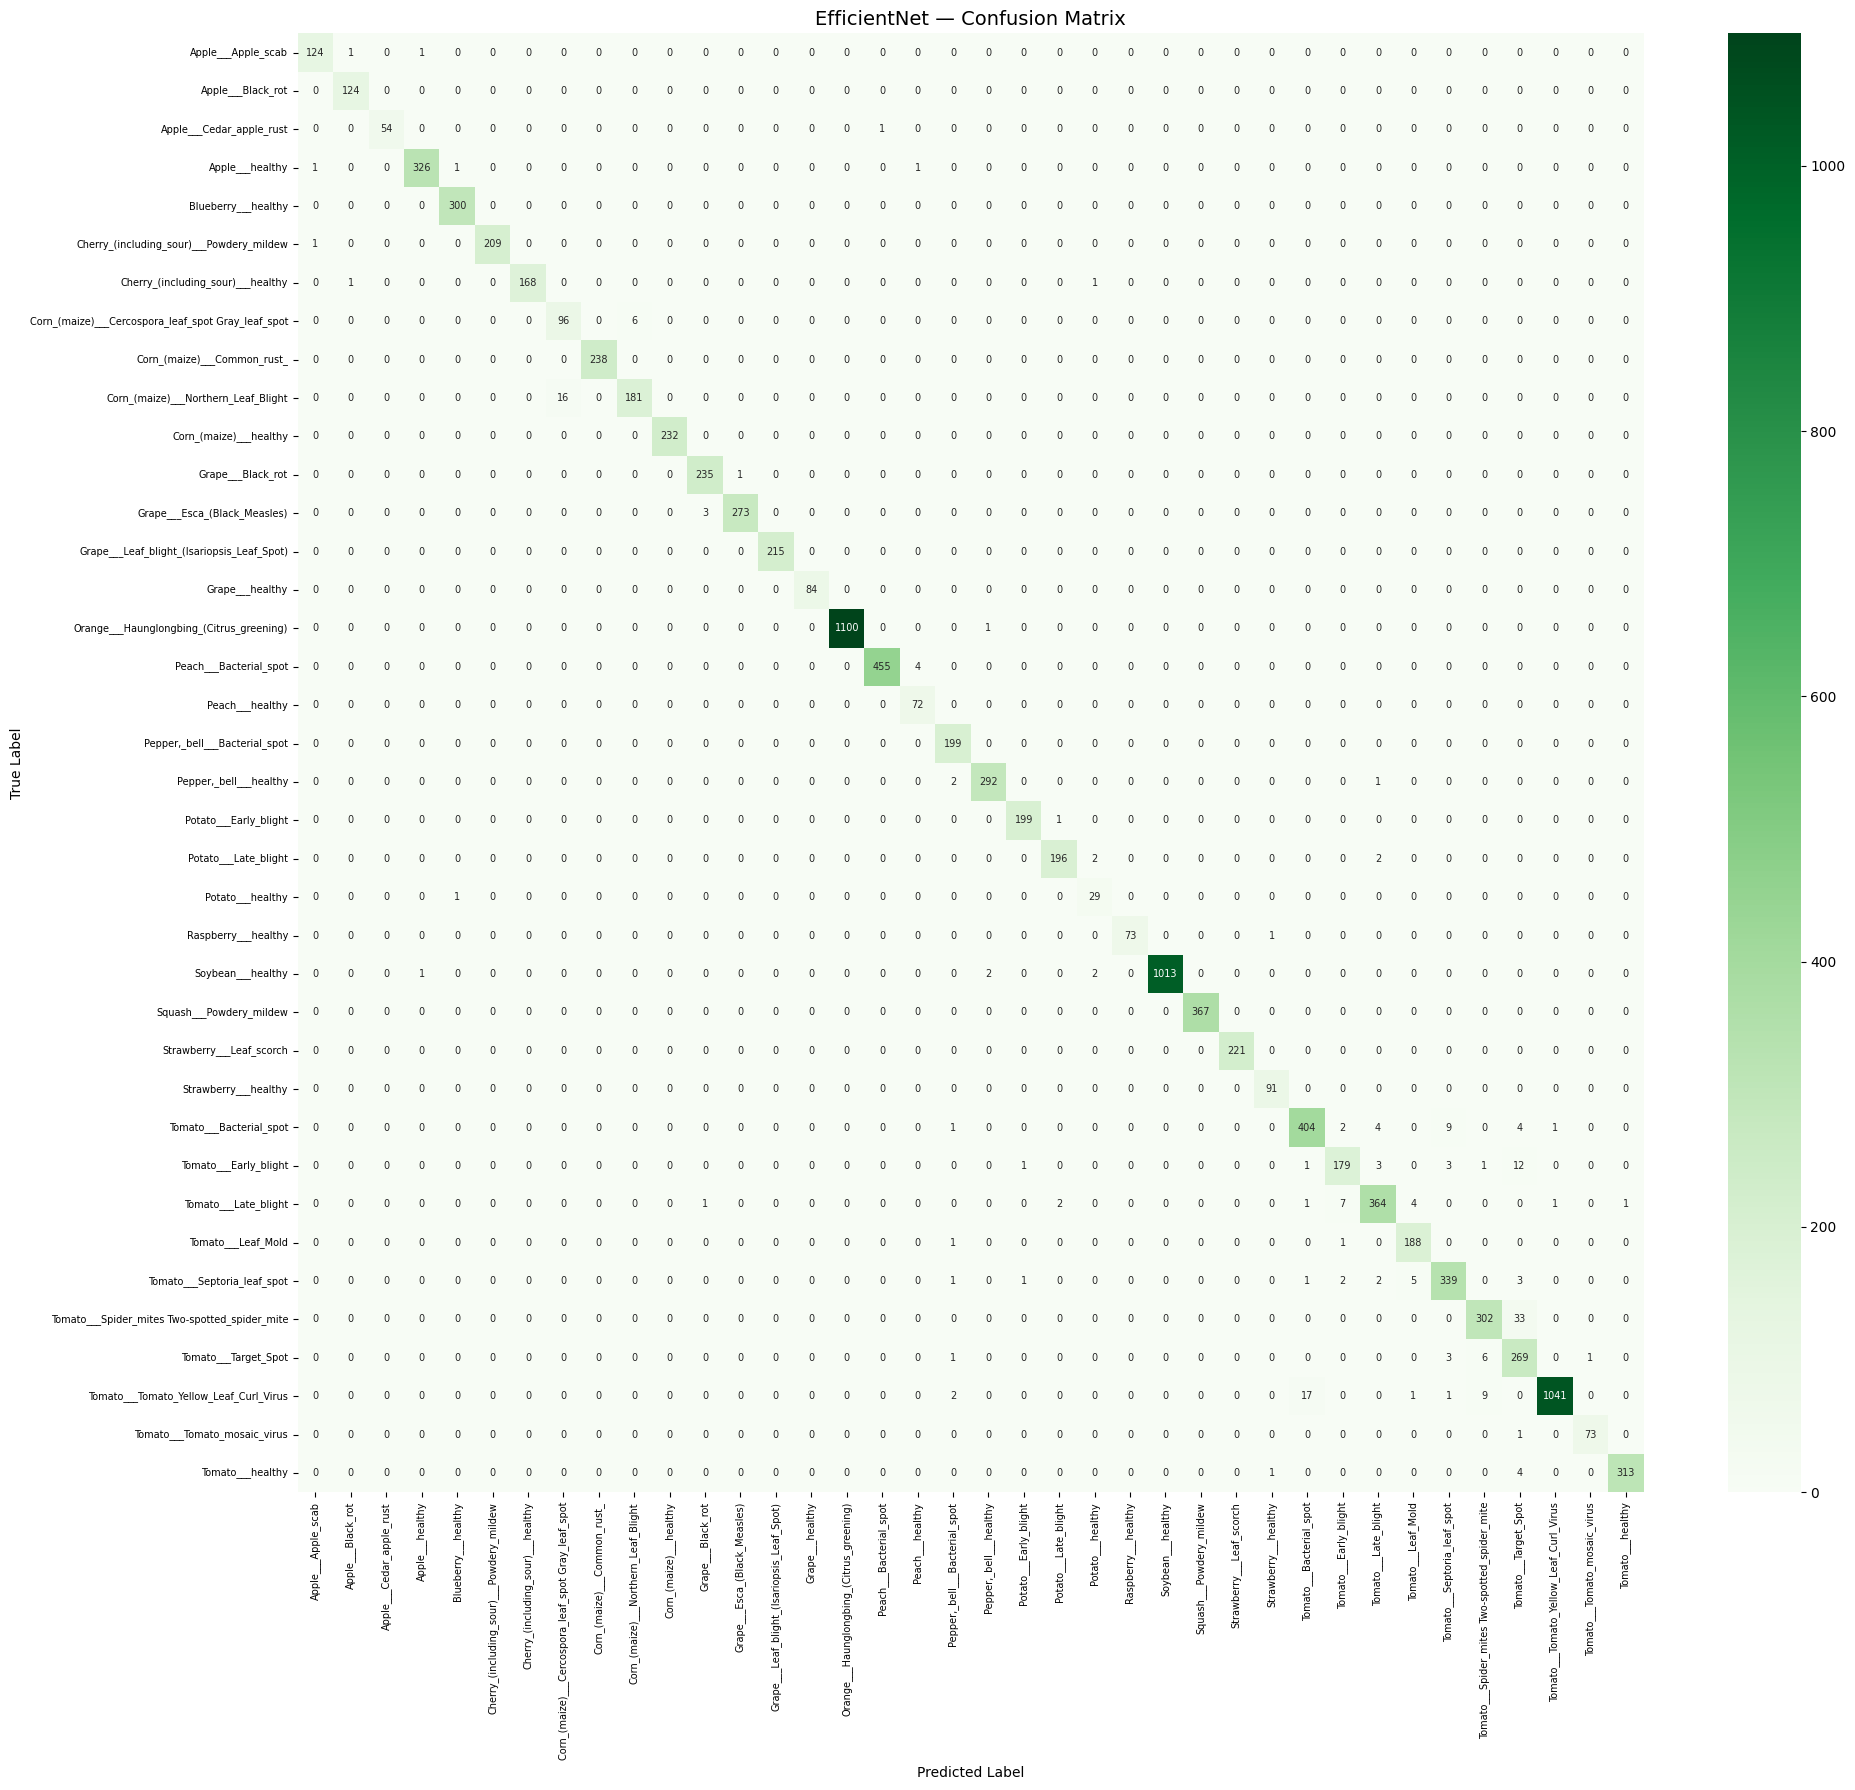

In [70]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 18))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_labels,
            yticklabels=class_labels,
            annot_kws={"size": 7})
plt.title("EfficientNet — Confusion Matrix", fontsize=14)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/efficientnet_confusion_matrix.png", dpi=150)
plt.show()

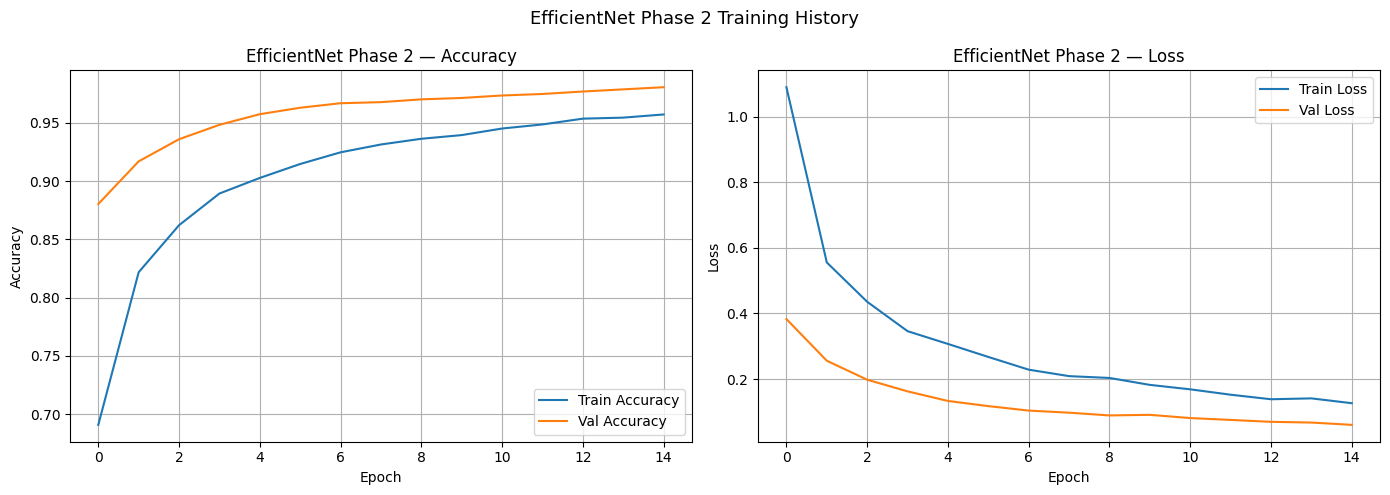

EfficientNet history saved!


In [71]:
# Plot EfficientNet training history
plot_history(phase2_history, "EfficientNet Phase 2")

# Save history
pd.DataFrame(phase2_history.history).to_csv(
    OUTPUT_DIR + "/efficientnet_history.csv", index=False)
print("EfficientNet history saved!")

# **Final Model Comparison Chart**

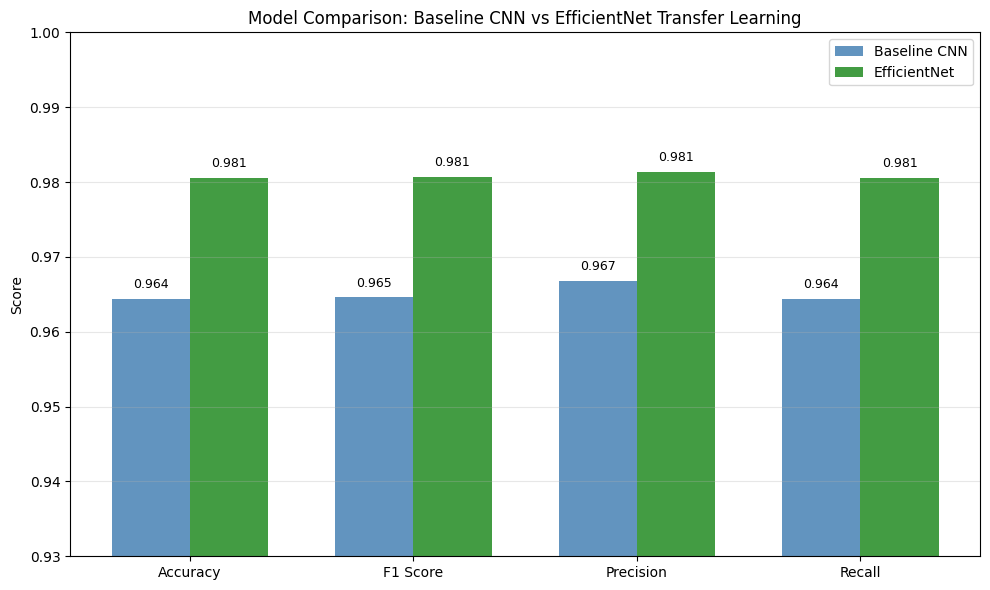

Comparison chart saved!


In [72]:
metrics = ['Accuracy', 'F1 Score', 'Precision', 'Recall']
baseline_scores = [0.9644, 0.9646, 0.9668, 0.9644]
efficientnet_scores = [0.9806, 0.9807, 0.9814, 0.9806]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline CNN', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, efficientnet_scores, width, label='EfficientNet', color='forestgreen', alpha=0.85)

ax.set_ylabel('Score')
ax.set_title('Model Comparison: Baseline CNN vs EfficientNet Transfer Learning')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.93, 1.00)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/model_comparison.png", dpi=150)
plt.show()
print("Comparison chart saved!")